# 1 · The data, and does the baseline reproduce?

Before testing any improvement, two things have to be true: the benchmark has to be
what the paper says it is, and our re-implementation of Min-K%++ has to return the
paper's numbers. If either fails, nothing downstream means anything.

**Min-K%++ in one line.** For each token, standardise its log-probability against the
mean and standard deviation of the model's own next-token distribution,

$$z_t = \frac{\log p(x_t \mid x_{<t}) - \mu_{\cdot|x_{<t}}}{\sigma_{\cdot|x_{<t}}},
\qquad \mu = \mathbb{E}_{v\sim p}[\log p(v)],$$

then average the lowest $k\%$ of the $z_t$. Higher score = more likely a training member.

In [1]:
import os, sys, importlib.util
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SCRIPTS, RES, FIG = ROOT/"scripts", ROOT/"results", ROOT/"results"/"figures"
sys.path.insert(0, str(SCRIPTS))
import minkpp as M
_s = importlib.util.spec_from_file_location("cachemod", SCRIPTS/"01_cache.py")
cachemod = importlib.util.module_from_spec(_s); _s.loader.exec_module(cachemod)

MODEL = os.environ.get("MINKPP_MODEL", "mamba-1.4b-hf")   # the paper's target model
SPLITS = ["WikiMIA_length32", "WikiMIA_length64", "WikiMIA_length128"]
pd.set_option("display.width", 120)
print("library self-check:", "PASS" if M.self_check(verbose=False) else "FAIL")


library self-check: PASS


## 1.1 The benchmark

WikiMIA labels membership by timestamp: Wikipedia event text written before a model's
training is a member, text written after is not. Two facts matter and are easy to miss,
so we count them by hand rather than trusting the split names.

In [2]:
rows = []
for sp in SPLITS:
    items, y = cachemod.load_cache(ROOT/"cache"/f"{MODEL}_{sp}_float32.npz")
    n = np.array([len(a) for a,_,_ in items])
    rows.append(dict(split=sp, items=len(items), members=int((y==1).sum()),
                     non_members=int((y==0).sum()),
                     tok_min=n.min(), tok_med=int(np.median(n)), tok_max=n.max(),
                     tok_sd=round(float(n.std()),1),
                     CV=round(float(n.std()/n.mean()),3)))
counts = pd.DataFrame(rows); counts

,split,items,members,non_members,tok_min,tok_med,tok_max,tok_sd,CV
0,WikiMIA_length32,776,387,389,32,41,129,9.2,0.213
1,WikiMIA_length64,542,284,258,69,84,167,11.2,0.131
2,WikiMIA_length128,250,139,111,142,168,272,16.1,0.095


**The split names are word counts, not token counts.** The "length 32" split spans
32 to 129 scored tokens — a 4x range *inside one split*. Any claim about how a method
behaves "at length 32" is really a claim about a distribution of lengths. This matters
directly for the hypotheses below, several of which are about length.

In [3]:
fig, ax = plt.subplots(figsize=(6.4,3.2))
for sp, col in zip(SPLITS, ["#2a78d6","#eb6834","#1baf7a"]):
    items, y = cachemod.load_cache(ROOT/"cache"/f"{MODEL}_{sp}_float32.npz")
    n = np.array([len(a) for a,_,_ in items])
    ax.hist(n, bins=40, alpha=.65, color=col, label=sp.replace("WikiMIA_",""))
ax.set_xlabel("scored tokens per item"); ax.set_ylabel("items")
ax.set_facecolor("#fcfcfb"); fig.set_facecolor("#fcfcfb")
for s in ("top","right"): ax.spines[s].set_visible(False)
ax.grid(color="#e4e3df", lw=.8); ax.set_axisbelow(True)
ax.legend(frameon=False); ax.set_title("Token counts overlap across splits", loc="left")
plt.show()

/tmp/ipykernel_1357094/4083207773.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Is length a label leak?** If members were systematically longer, a method sensitive
to length would look good for the wrong reason. Check it.

In [4]:
for sp in SPLITS:
    items, y = cachemod.load_cache(ROOT/"cache"/f"{MODEL}_{sp}_float32.npz")
    n = np.array([len(a) for a,_,_ in items])
    print(f"{sp:24s} median tokens  member {np.median(n[y==1]):6.1f}   "
          f"non-member {np.median(n[y==0]):6.1f}")

WikiMIA_length32         median tokens  member   41.0   non-member   42.0
WikiMIA_length64         median tokens  member   84.0   non-member   84.0
WikiMIA_length128        median tokens  member  168.0   non-member  169.0


Balanced. Length is a **nuisance**, not a leak — it can add noise but it cannot by
itself separate the classes.

## 1.2 Per-token quantities

Everything in this study is a function of three cached numbers per token. The model is
run **once** per split; every variant is then post-processing. That is what makes the
baseline and the variants comparable at exactly matched compute — no variant can win by
having had a different forward pass.

In [5]:
items, y = cachemod.load_cache(ROOT/"cache"/f"{MODEL}_WikiMIA_length32_float32.npz")
logp, mu, sigma = items[0]
z = M.zscores(logp, mu, sigma)
print(f"item 0: {len(logp)} scored tokens")
pd.DataFrame({"logp": logp[:8], "mu": mu[:8], "sigma": sigma[:8], "z": z[:8]}).round(3)

item 0: 39 scored tokens


,logp,mu,sigma,z
0,-9.106,-8.520,1.995,-0.293
1,-1.756,-4.950,3.817,0.837
2,-9.886,-6.376,2.679,-1.310
3,-11.838,-4.778,3.248,-2.174
4,-9.995,-4.805,2.976,-1.744
5,-4.532,-6.381,2.611,0.708
6,-4.793,-4.395,2.438,-0.163
7,-1.070,-2.620,2.242,0.691


The z-score is *not* a monotone transform of `logp` — it depends on the shape of the
whole next-token distribution. Confusing the two is the one bug that would silently turn
Min-K%++ back into Min-K% while still looking plausible, so the library asserts it.

In [6]:
print("corr(logp, z) =", round(float(np.corrcoef(logp, z)[0,1]), 3))
print("identical?", np.allclose(logp, z))

corr(logp, z) = 0.811
identical? False


## 1.3 Does the baseline reproduce?

In [7]:
auroc = pd.read_csv(RES/f"auroc_{MODEL}.csv")
base = auroc[auroc.variant.isin(["loss","zlib","mink_0.2","minkpp_0.2"])]
piv = base.pivot(index="variant", columns="split", values="auroc").round(1)
piv = piv.reindex(["loss","zlib","mink_0.2","minkpp_0.2"])
piv

split,WikiMIA_length128,WikiMIA_length32,WikiMIA_length64
variant,,,
loss,63.3,61.0,58.2
zlib,67.2,64.2,62.7
mink_0.2,67.0,63.1,61.4
minkpp_0.2,67.9,66.4,67.0


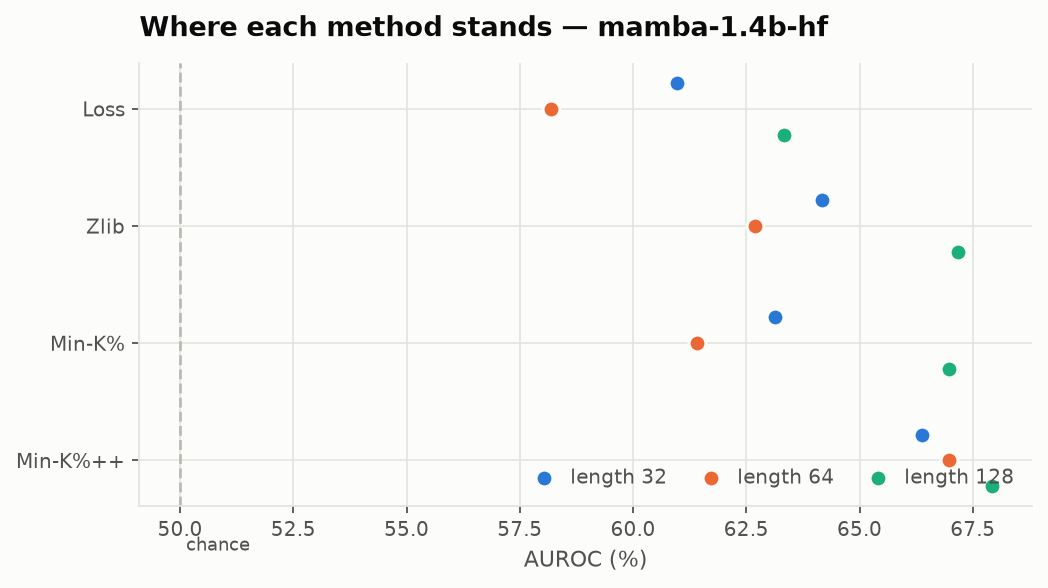

In [8]:
display(Image(filename=str(FIG/f"fig1_baseline_{MODEL}.png")))

### What to read here

Against the published Mamba-1.4B column (66.8 / 67.2 / 68.8 for Min-K%++), a small model
scores far lower and the Min-K%++ advantage over Min-K% largely disappears. That is
consistent with the paper's own Table 1: its gain averages **+3.7** over Mamba-1.4B and
Pythia-6.9B but **+13.6** over the three LLaMA columns. The method's advantage grows with
model scale, and the models inside a student budget are the ones where it helps least.

This is a finding about the experiment's sensitivity, and it shapes how the next notebook
should be read: on a model where the baseline barely works, there is little signal for an
aggregation variant to improve.

## 1.4 What the benchmark can resolve

A difference smaller than the benchmark's own sampling noise is not a result. We measure
the noise rather than assume it.

In [9]:
pd.read_csv(RES/f"resolution_{MODEL}.csv").round(2)

,split,n,single_auroc_halfwidth
0,WikiMIA_length32,776,3.74
1,WikiMIA_length64,542,4.45
2,WikiMIA_length128,250,6.48


Several gaps reported in the source papers are **smaller than this half-width**.
Any improvement we claim has to clear it, which is why every comparison below uses a
*paired* bootstrap: sharing the resample indices between the two methods removes the
part of the noise that is common to both and materially narrows the interval.